In [1]:

# StockSense - Install Required Libraries

!pip install yfinance plotly scikit-learn pandas numpy matplotlib seaborn -q

print("StockSense libraries installed successfully!")


StockSense libraries installed successfully!


In [2]:

import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

print("All libraries imported successfully!")
print("Welcome to StockSense!")


All libraries imported successfully!
Welcome to StockSense!


In [3]:

# STOCK DATA COLLECTION

stock_symbol = "RELIANCE.NS"

stock_data = yf.download(
    stock_symbol,
    period="2y",
    interval="1d",
    auto_adjust=True
)

print("Stock data downloaded successfully!")

print(stock_data.head())


[*********************100%***********************]  1 of 1 completed

Stock data downloaded successfully!
Price             Close         High          Low         Open      Volume
Ticker      RELIANCE.NS  RELIANCE.NS  RELIANCE.NS  RELIANCE.NS RELIANCE.NS
Date                                                                      
2024-11-18  1249.955444  1262.001440  1233.249738  1256.746770    13620611
2024-11-19  1231.018921  1270.527698  1224.574574  1249.955361    14183746
2024-11-21  1212.528687  1233.299264  1206.827918  1231.019030    19433843
2024-11-22  1254.565552  1257.985964  1211.983221  1218.873787    20471957
2024-11-25  1275.980591  1293.281134  1271.469500  1278.954905    28923341


In [4]:

print("Dataset Shape:", stock_data.shape)

print("\nColumn Names:")
print(stock_data.columns)

print("\nDataset Information:")
print(stock_data.info())

print("\nStatistical Summary:")
print(stock_data.describe())


Dataset Shape: (495, 5)

Column Names:
MultiIndex([( 'Close', 'RELIANCE.NS'),
            (  'High', 'RELIANCE.NS'),
            (   'Low', 'RELIANCE.NS'),
            (  'Open', 'RELIANCE.NS'),
            ('Volume', 'RELIANCE.NS')],
           names=['Price', 'Ticker'])

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 495 entries, 2024-11-18 to 2026-11-17
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   (Close, RELIANCE.NS)   494 non-null    float64
 1   (High, RELIANCE.NS)    494 non-null    float64
 2   (Low, RELIANCE.NS)     494 non-null    float64
 3   (Open, RELIANCE.NS)    494 non-null    float64
 4   (Volume, RELIANCE.NS)  495 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 23.2 KB
None

Statistical Summary:
Price         Close         High          Low         Open        Volume
Ticker  RELIANCE.NS  RELIANCE.NS  RELIANCE.NS  RELIANCE.NS   RELIAN

In [5]:

# CHECK MISSING VALUES

print("Missing Values:")
print(stock_data.isnull().sum())

print("\nDuplicate Rows:")
print(stock_data.duplicated().sum())


Missing Values:
Price   Ticker     
Close   RELIANCE.NS    1
High    RELIANCE.NS    1
Low     RELIANCE.NS    1
Open    RELIANCE.NS    1
Volume  RELIANCE.NS    0
dtype: int64

Duplicate Rows:
0


In [6]:

# DATA CLEANING

stock_data = stock_data.copy()

stock_data = stock_data.dropna()

stock_data = stock_data[~stock_data.index.duplicated(keep="first")]

print("Data Cleaning Completed!")
print("Clean Dataset Shape:", stock_data.shape)

print(stock_data.head())


Data Cleaning Completed!
Clean Dataset Shape: (494, 5)
Price             Close         High          Low         Open      Volume
Ticker      RELIANCE.NS  RELIANCE.NS  RELIANCE.NS  RELIANCE.NS RELIANCE.NS
Date                                                                      
2024-11-18  1249.955444  1262.001440  1233.249738  1256.746770    13620611
2024-11-19  1231.018921  1270.527698  1224.574574  1249.955361    14183746
2024-11-21  1212.528687  1233.299264  1206.827918  1231.019030    19433843
2024-11-22  1254.565552  1257.985964  1211.983221  1218.873787    20471957
2024-11-25  1275.980591  1293.281134  1271.469500  1278.954905    28923341


In [7]:

# BASIC STOCK ANALYSIS

print("Average Closing Price:", stock_data["Close"].mean())

print("Maximum Closing Price:", stock_data["Close"].max())

print("Minimum Closing Price:", stock_data["Close"].min())

print("Average Trading Volume:", stock_data["Volume"].mean())


Average Closing Price: Ticker
RELIANCE.NS    1349.166904
dtype: float64
Maximum Closing Price: Ticker
RELIANCE.NS    1584.971802
dtype: float64
Minimum Closing Price: Ticker
RELIANCE.NS    1151.951782
dtype: float64
Average Trading Volume: Ticker
RELIANCE.NS    1.330437e+07
dtype: float64


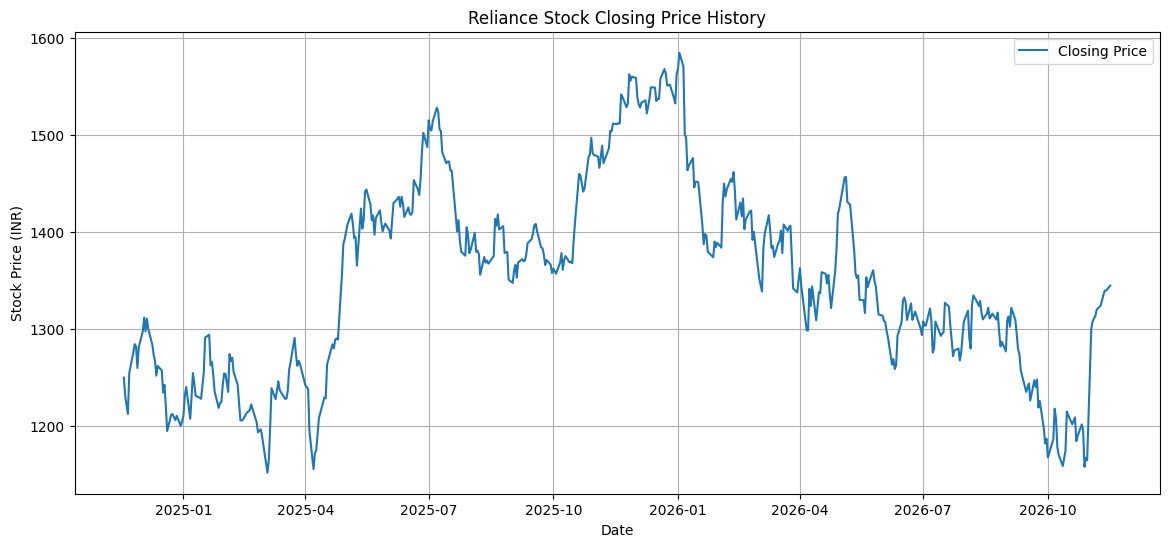

In [8]:

# STOCK CLOSING PRICE VISUALIZATION

plt.figure(figsize=(14, 6))

plt.plot(
    stock_data.index,
    stock_data["Close"],
    label="Closing Price"
)

plt.title("Reliance Stock Closing Price History")
plt.xlabel("Date")
plt.ylabel("Stock Price (INR)")

plt.legend()
plt.grid(True)

plt.show()


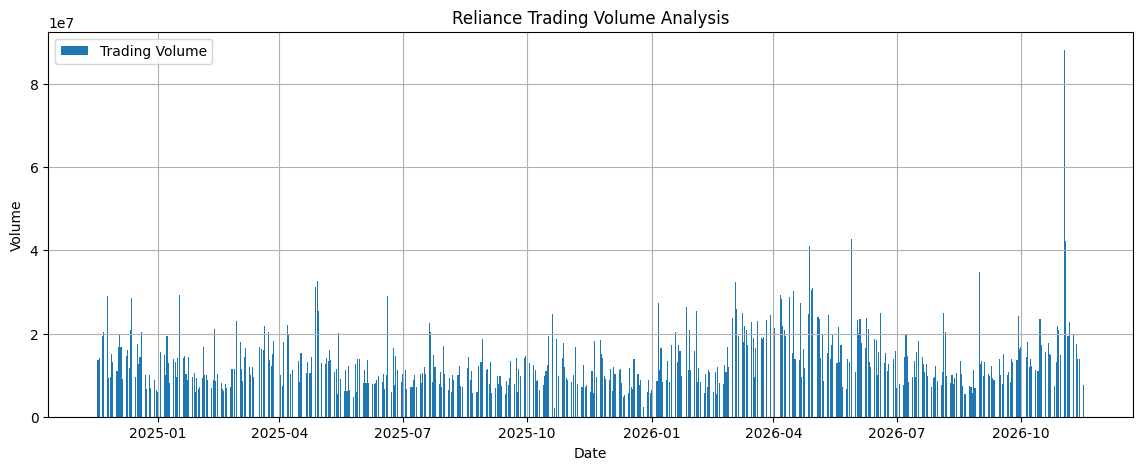

In [11]:

# STEP 12: TRADING VOLUME ANALYSIS

# Convert Volume into a 1D Series
volume = stock_data["Volume"]

if isinstance(volume, pd.DataFrame):
    volume = volume.iloc[:, 0]

volume = pd.to_numeric(volume, errors="coerce")

plt.figure(figsize=(14, 5))

plt.bar(
    stock_data.index,
    volume.to_numpy(),
    label="Trading Volume"
)

plt.title("Reliance Trading Volume Analysis")
plt.xlabel("Date")
plt.ylabel("Volume")

plt.legend()
plt.grid(True)
plt.show()


Price             Close Daily_Return
Ticker      RELIANCE.NS             
Date                                
2026-11-02  1300.000000    11.597560
2026-11-03  1307.900024     0.607694
2026-11-04  1311.000000     0.237019
2026-11-05  1313.400024     0.183068
2026-11-06  1320.000000     0.502511
2026-11-09  1324.400024     0.333335
2026-11-11  1335.400024     0.830565
2026-11-12  1339.699951     0.321995
2026-11-13  1339.699951     0.000000
2026-11-16  1344.800049     0.380690


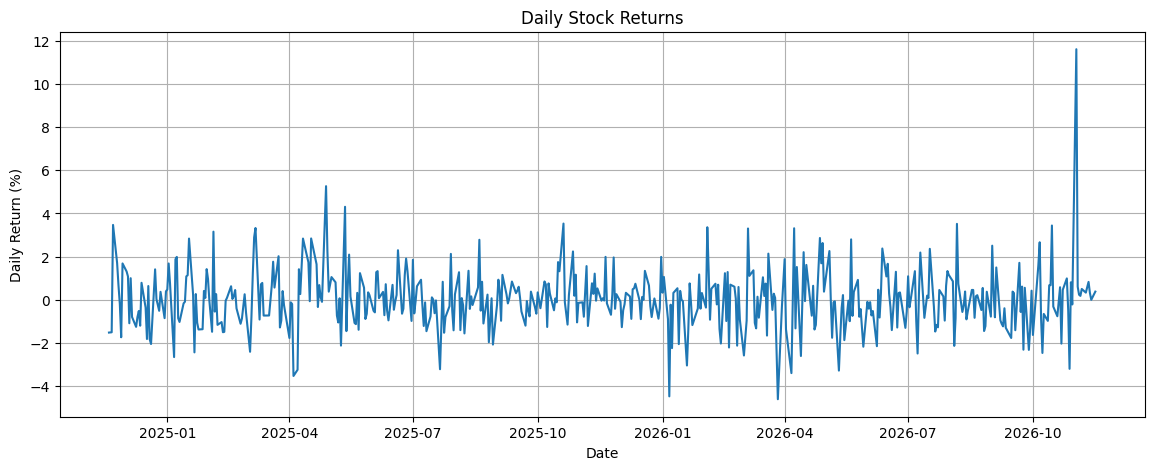

In [12]:

# DAILY RETURNS

stock_data["Daily_Return"] = (
    stock_data["Close"].pct_change() * 100
)

print(stock_data[["Close", "Daily_Return"]].tail(10))

plt.figure(figsize=(14, 5))

plt.plot(
    stock_data.index,
    stock_data["Daily_Return"]
)

plt.title("Daily Stock Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")

plt.grid(True)
plt.show()


In [13]:

# STEP 14: PREPARE STOCK DATA

# Flatten columns if Yahoo Finance returned MultiIndex columns
if isinstance(stock_data.columns, pd.MultiIndex):
    stock_data.columns = stock_data.columns.get_level_values(0)

stock_data = stock_data.copy()
stock_data = stock_data.dropna()

print("Stock data prepared successfully!")
print(stock_data.head())


Stock data prepared successfully!
Price             Close         High          Low         Open    Volume  \
Date                                                                       
2024-11-19  1231.018921  1270.527698  1224.574574  1249.955361  14183746   
2024-11-21  1212.528687  1233.299264  1206.827918  1231.019030  19433843   
2024-11-22  1254.565552  1257.985964  1211.983221  1218.873787  20471957   
2024-11-25  1275.980591  1293.281134  1271.469500  1278.954905  28923341   
2024-11-26  1284.606201  1286.737817  1273.204664  1283.862623   9247557   

Price       Daily_Return  
Date                      
2024-11-19     -1.514976  
2024-11-21     -1.502027  
2024-11-22      3.466876  
2024-11-25      1.706969  
2024-11-26      0.675999  


In [14]:

# STEP 15: SIMPLE MOVING AVERAGE

stock_data["SMA_20"] = stock_data["Close"].rolling(window=20).mean()

stock_data["SMA_50"] = stock_data["Close"].rolling(window=50).mean()

print(stock_data[["Close", "SMA_20", "SMA_50"]].tail(10))


Price             Close       SMA_20       SMA_50
Date                                             
2026-11-02  1300.000000  1193.029999  1235.663999
2026-11-03  1307.900024  1199.104999  1235.558000
2026-11-04  1311.000000  1203.754999  1235.458000
2026-11-05  1313.400024  1209.040002  1235.530000
2026-11-06  1320.000000  1216.140002  1235.590000
2026-11-09  1324.400024  1223.845001  1236.118000
2026-11-11  1335.400024  1232.670001  1237.182002
2026-11-12  1339.699951  1241.320001  1238.236001
2026-11-13  1339.699951  1249.575000  1239.490000
2026-11-16  1344.800049  1256.065002  1240.206001


In [15]:

# STEP 16: EXPONENTIAL MOVING AVERAGE

stock_data["EMA_12"] = stock_data["Close"].ewm(span=12, adjust=False).mean()

stock_data["EMA_26"] = stock_data["Close"].ewm(span=26, adjust=False).mean()

print(stock_data[["Close", "EMA_12", "EMA_26"]].tail(10))


Price             Close       EMA_12       EMA_26
Date                                             
2026-11-02  1300.000000  1201.279985  1206.455526
2026-11-03  1307.900024  1217.683068  1213.969933
2026-11-04  1311.000000  1232.039519  1221.157345
2026-11-05  1313.400024  1244.556520  1227.990136
2026-11-06  1320.000000  1256.163209  1234.805682
2026-11-09  1324.400024  1266.661181  1241.442300
2026-11-11  1335.400024  1277.236387  1248.402131
2026-11-12  1339.699951  1286.846166  1255.164933
2026-11-13  1339.699951  1294.977518  1261.426786
2026-11-16  1344.800049  1302.642523  1267.602583


In [16]:

# STEP 17: RELATIVE STRENGTH INDEX

delta = stock_data["Close"].diff()

gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
avg_loss = loss.ewm(alpha=1/14, min_periods=14, adjust=False).mean()

rs = avg_gain / avg_loss.replace(0, np.nan)

stock_data["RSI"] = 100 - (100 / (1 + rs))

# Handle periods with no losses
stock_data.loc[(avg_loss == 0) & (avg_gain > 0), "RSI"] = 100

print(stock_data[["Close", "RSI"]].tail(10))


Price             Close        RSI
Date                              
2026-11-02  1300.000000  65.780566
2026-11-03  1307.900024  66.676778
2026-11-04  1311.000000  67.041548
2026-11-05  1313.400024  67.339630
2026-11-06  1320.000000  68.191595
2026-11-09  1324.400024  68.776360
2026-11-11  1335.400024  70.248893
2026-11-12  1339.699951  70.828055
2026-11-13  1339.699951  70.828055
2026-11-16  1344.800049  71.588859


In [17]:

# STEP 18: MACD CALCULATION

stock_data["MACD"] = stock_data["EMA_12"] - stock_data["EMA_26"]

stock_data["MACD_Signal"] = stock_data["MACD"].ewm(
    span=9,
    adjust=False
).mean()

print(stock_data[["MACD", "MACD_Signal"]].tail(10))


Price            MACD  MACD_Signal
Date                              
2026-11-02  -5.175541   -13.832685
2026-11-03   3.713135   -10.323521
2026-11-04  10.882174    -6.082382
2026-11-05  16.566383    -1.552629
2026-11-06  21.357527     3.029402
2026-11-09  25.218881     7.467298
2026-11-11  28.834256    11.740690
2026-11-12  31.681234    15.728799
2026-11-13  33.550732    19.293185
2026-11-16  35.039939    22.442536


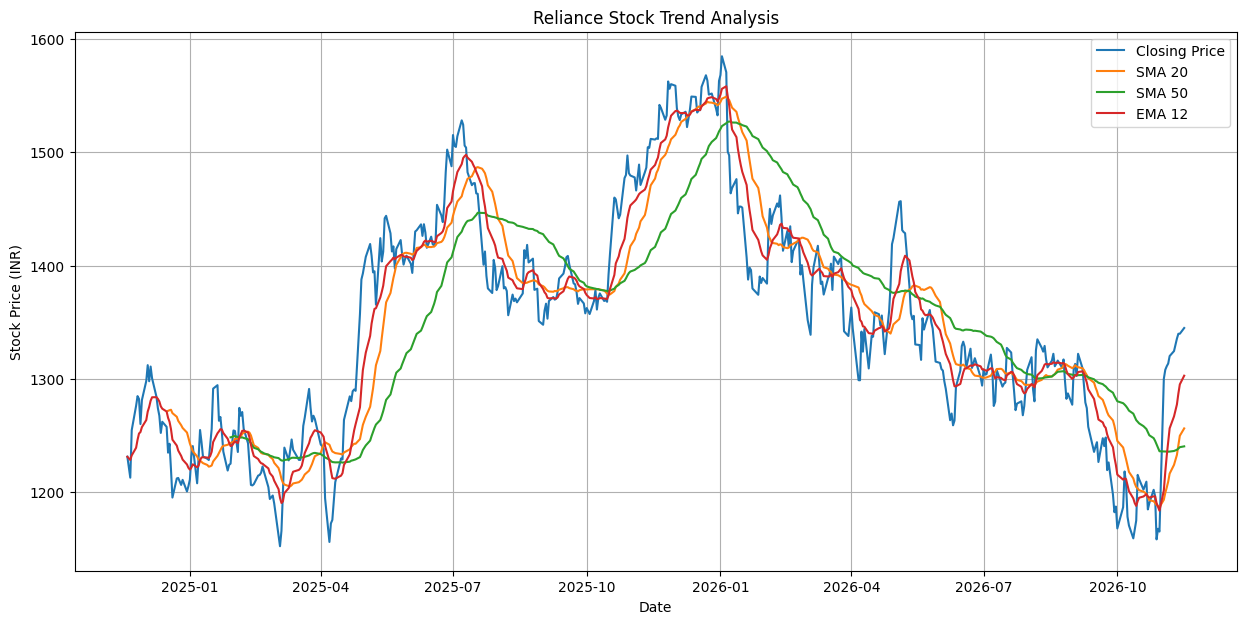

In [18]:

# STEP 19: STOCK PRICE WITH SMA AND EMA

plt.figure(figsize=(15, 7))

plt.plot(stock_data.index, stock_data["Close"], label="Closing Price")

plt.plot(stock_data.index, stock_data["SMA_20"], label="SMA 20")

plt.plot(stock_data.index, stock_data["SMA_50"], label="SMA 50")

plt.plot(stock_data.index, stock_data["EMA_12"], label="EMA 12")

plt.title("Reliance Stock Trend Analysis")

plt.xlabel("Date")
plt.ylabel("Stock Price (INR)")

plt.legend()
plt.grid(True)
plt.show()


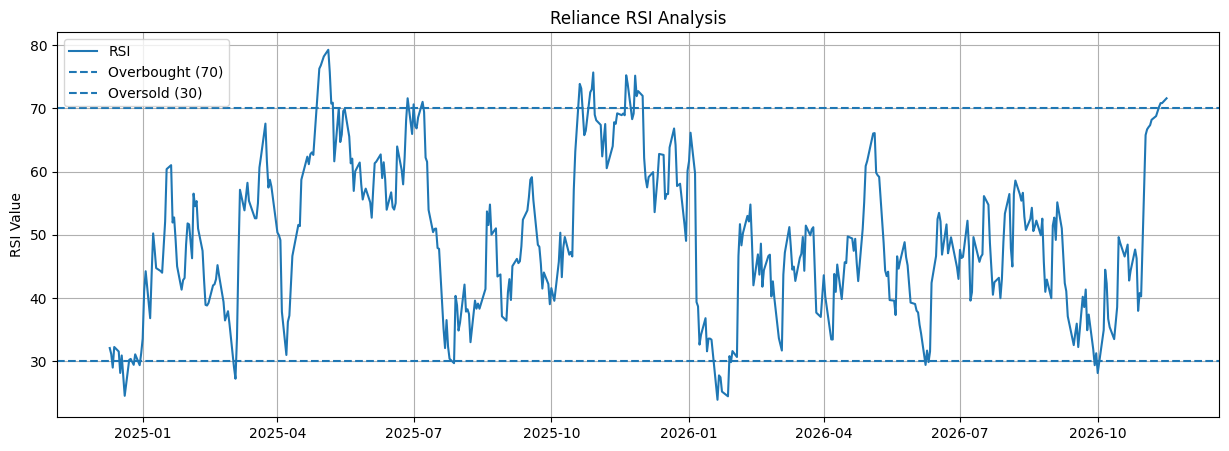

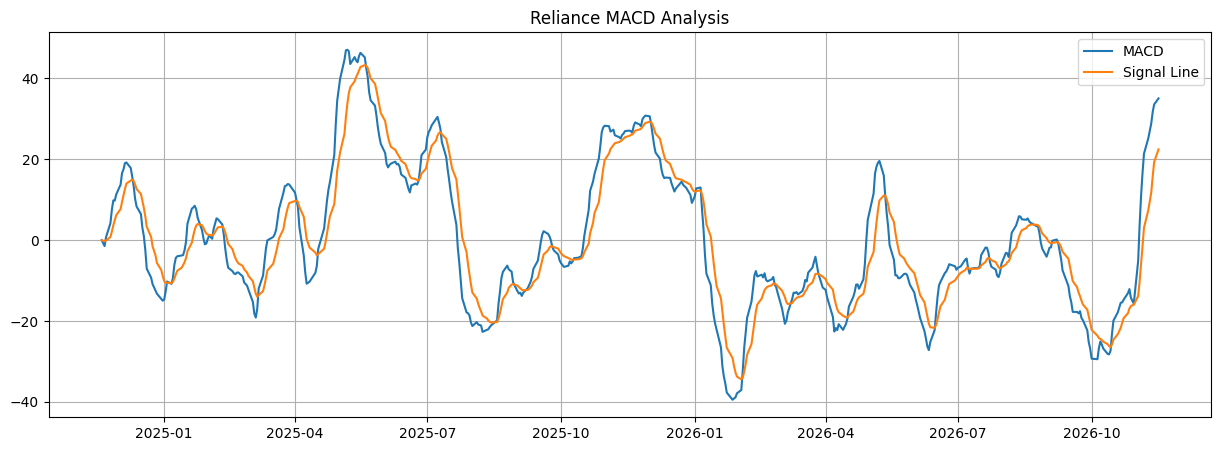

In [19]:

# RSI VISUALIZATION

plt.figure(figsize=(15, 5))

plt.plot(stock_data.index, stock_data["RSI"], label="RSI")

plt.axhline(70, linestyle="--", label="Overbought (70)")
plt.axhline(30, linestyle="--", label="Oversold (30)")

plt.title("Reliance RSI Analysis")
plt.ylabel("RSI Value")

plt.legend()
plt.grid(True)
plt.show()


# MACD VISUALIZATION

plt.figure(figsize=(15, 5))

plt.plot(stock_data.index, stock_data["MACD"], label="MACD")
plt.plot(stock_data.index, stock_data["MACD_Signal"], label="Signal Line")

plt.title("Reliance MACD Analysis")

plt.legend()
plt.grid(True)
plt.show()


In [20]:

# STEP 21: MARKET TREND DETECTION

def identify_trend(row):

    if row["SMA_20"] > row["SMA_50"] and row["MACD"] > row["MACD_Signal"]:
        return "Bullish"

    elif row["SMA_20"] < row["SMA_50"] and row["MACD"] < row["MACD_Signal"]:
        return "Bearish"

    else:
        return "Sideways"

stock_data["Market_Trend"] = stock_data.apply(
    identify_trend,
    axis=1
)

print(stock_data[["Close", "SMA_20", "SMA_50", "RSI", "Market_Trend"]].tail(15))


Price             Close       SMA_20       SMA_50        RSI Market_Trend
Date                                                                     
2026-10-26  1201.800049  1191.719995  1247.453999  47.686437     Sideways
2026-10-27  1196.199951  1190.229993  1245.037998  46.270558     Sideways
2026-10-28  1158.000000  1188.249994  1241.997998  37.985417     Sideways
2026-10-29  1167.400024  1187.519995  1239.025999  40.794769     Sideways
2026-10-30  1164.900024  1186.414996  1235.883999  40.272236     Sideways
2026-11-02  1300.000000  1193.029999  1235.663999  65.780566     Sideways
2026-11-03  1307.900024  1199.104999  1235.558000  66.676778     Sideways
2026-11-04  1311.000000  1203.754999  1235.458000  67.041548     Sideways
2026-11-05  1313.400024  1209.040002  1235.530000  67.339630     Sideways
2026-11-06  1320.000000  1216.140002  1235.590000  68.191595     Sideways
2026-11-09  1324.400024  1223.845001  1236.118000  68.776360     Sideways
2026-11-11  1335.400024  1232.670001  

In [21]:

# STEP 22: PREPARE MACHINE LEARNING DATASET

# Calculate required features
stock_data["Daily_Return"] = stock_data["Close"].pct_change() * 100

stock_data["Volatility"] = stock_data["Daily_Return"].rolling(20).std()

stock_data["Volume_Change"] = stock_data["Volume"].pct_change() * 100

# Create target variable
# 1 = Next session price goes UP
# 0 = Next session price goes DOWN or stays equal

stock_data["Target"] = (
    stock_data["Close"].shift(-1) > stock_data["Close"]
).astype(int)

features = [
    "Daily_Return",
    "RSI",
    "MACD",
    "SMA_20",
    "SMA_50",
    "Volume_Change",
    "Volatility"
]

ml_data = stock_data[features + ["Target"]].replace(
    [np.inf, -np.inf], np.nan
).dropna()

print("Machine Learning Dataset Created!")
print(ml_data.head())

print("\nDataset Shape:", ml_data.shape)


Machine Learning Dataset Created!
Price       Daily_Return        RSI      MACD       SMA_20       SMA_50  \
Date                                                                      
2025-01-29      0.089102  43.183734 -1.044559  1243.213647  1248.211489   
2025-01-30      1.420481  48.487205 -0.824090  1243.771332  1248.437539   
2025-01-31      0.961649  51.813098  0.311054  1244.462854  1249.272329   
2025-02-01     -0.039523  51.664039  1.157321  1246.772906  1249.256467   
2025-02-03     -1.478721  46.299397  0.328204  1247.023254  1248.441509   

Price       Volume_Change  Volatility  Target  
Date                                           
2025-01-29     -43.904788    1.472018       1  
2025-01-30      56.359903    1.457983       1  
2025-01-31     -28.962908    1.463974       0  
2025-02-01       8.107403    1.318277       0  
2025-02-03      29.976906    1.306657       1  

Dataset Shape: (442, 8)


In [22]:

# STEP 23: TRAINING AND TESTING DATA

X = ml_data[features]
y = ml_data["Target"]

split_index = int(len(ml_data) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training and testing split completed!")


Training samples: 353
Testing samples: 89
Training and testing split completed!


In [23]:

# STEP 24: RANDOM FOREST CLASSIFIER

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    min_samples_leaf=3,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")


Random Forest Model Trained Successfully!


In [24]:

# STEP 25: MODEL PREDICTIONS

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
}, index=y_test.index)

results["Actual"] = results["Actual"].map({
    0: "DOWN",
    1: "UP"
})

results["Predicted"] = results["Predicted"].map({
    0: "DOWN",
    1: "UP"
})

print(results.head(15))


           Actual Predicted
Date                       
2026-07-09     UP        UP
2026-07-10   DOWN      DOWN
2026-07-13   DOWN        UP
2026-07-14     UP        UP
2026-07-15     UP        UP
2026-07-16     UP        UP
2026-07-17   DOWN      DOWN
2026-07-20   DOWN      DOWN
2026-07-21   DOWN      DOWN
2026-07-22   DOWN        UP
2026-07-23     UP        UP
2026-07-24     UP        UP
2026-07-27   DOWN        UP
2026-07-28     UP        UP
2026-07-29     UP        UP


In [25]:

# STEP 26: MODEL ACCURACY

accuracy = accuracy_score(y_test, y_pred)

print("StockSense Model Accuracy:")
print(f"{accuracy * 100:.2f}%")


StockSense Model Accuracy:
59.55%


In [26]:

# STEP 27: CLASSIFICATION REPORT

print(classification_report(
    y_test,
    y_pred,
    target_names=["DOWN", "UP"],
    zero_division=0
))


              precision    recall  f1-score   support

        DOWN       0.61      0.47      0.53        43
          UP       0.59      0.72      0.65        46

    accuracy                           0.60        89
   macro avg       0.60      0.59      0.59        89
weighted avg       0.60      0.60      0.59        89



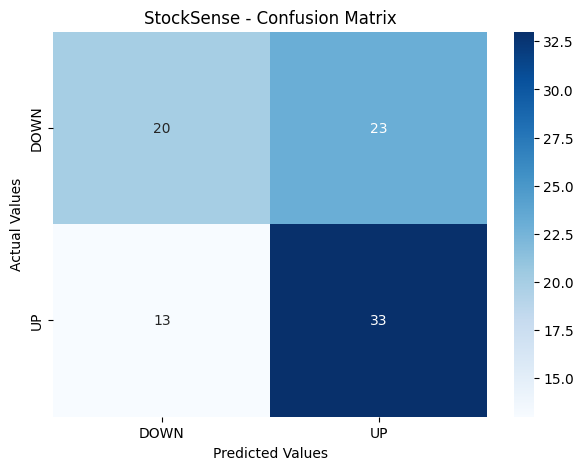

In [27]:

# STEP 28: CONFUSION MATRIX

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["DOWN", "UP"],
    yticklabels=["DOWN", "UP"]
)

plt.title("StockSense - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()


         Feature  Importance
5  Volume_Change    0.169977
6     Volatility    0.143376
2           MACD    0.141973
0   Daily_Return    0.139477
1            RSI    0.139106
4         SMA_50    0.134999
3         SMA_20    0.131092


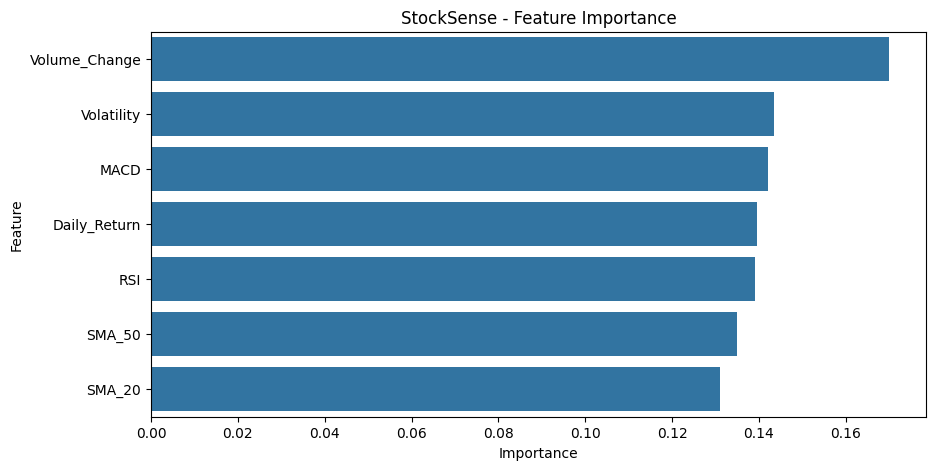

In [28]:

# STEP 29: FEATURE IMPORTANCE

importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("StockSense - Feature Importance")
plt.show()


In [29]:

# STEP 30: NEXT SESSION DIRECTION PREDICTION

final_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    min_samples_leaf=3,
    random_state=42,
    class_weight="balanced"
)

# Train using all historical rows with known targets
final_model.fit(X, y)

# Get latest available feature values
latest_features = stock_data[features].replace(
    [np.inf, -np.inf], np.nan
).dropna().iloc[[-1]]

prediction = final_model.predict(latest_features)[0]

probabilities = final_model.predict_proba(latest_features)[0]

print("===================================")
print("       STOCKSENSE PREDICTION")
print("===================================")

if prediction == 1:
    print("Predicted Direction: UP")
else:
    print("Predicted Direction: DOWN")

print(f"Probability of DOWN: {probabilities[0]*100:.2f}%")
print(f"Probability of UP: {probabilities[1]*100:.2f}%")

print("===================================")
print("Educational prediction, not financial advice.")


       STOCKSENSE PREDICTION
Predicted Direction: UP
Probability of DOWN: 42.79%
Probability of UP: 57.21%
Educational prediction, not financial advice.


In [30]:

# PHASE 6 - STOCKSENSE DASHBOARD

import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Latest stock information
latest_price = stock_data["Close"].iloc[-1]
previous_price = stock_data["Close"].iloc[-2]

daily_change = (
    (latest_price - previous_price) / previous_price
) * 100

latest_rsi = stock_data["RSI"].iloc[-1]

latest_trend = stock_data["Market_Trend"].iloc[-1]

# Dashboard heading
print("=" * 50)
print("          STOCKSENSE DASHBOARD")
print("=" * 50)

print(f"Stock: RELIANCE.NS")
print(f"Latest Closing Price: ₹{latest_price:.2f}")
print(f"Daily Change: {daily_change:.2f}%")
print(f"RSI: {latest_rsi:.2f}")
print(f"Market Trend: {latest_trend}")
print(f"ML Prediction: {'UP' if prediction == 1 else 'DOWN'}")

print("=" * 50)


          STOCKSENSE DASHBOARD
Stock: RELIANCE.NS
Latest Closing Price: ₹1344.80
Daily Change: 0.38%
RSI: 71.59
Market Trend: Bullish
ML Prediction: UP


In [33]:

# INTERACTIVE STOCK PRICE CHART

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=stock_data.index,
    y=stock_data["Close"],
    name="Closing Price",
    line=dict(width=2)
))

fig.add_trace(go.Scatter(
    x=stock_data.index,
    y=stock_data["SMA_20"],
    name="SMA 20"
))

fig.add_trace(go.Scatter(
    x=stock_data.index,
    y=stock_data["SMA_50"],
    name="SMA 50"
))

fig.update_layout(
    title="StockSense - Reliance Stock Analysis",
    xaxis_title="Date",
    yaxis_title="Price (INR)",
    template="plotly_dark",
    height=550,
    hovermode="x unified"
)

fig.show()


In [34]:

# STEP 33: STOCK SEARCH FUNCTION

def analyze_stock(symbol):

    data = yf.download(
        symbol,
        period="1y",
        interval="1d",
        auto_adjust=True,
        progress=False
    )

    if data.empty:
        print("Invalid stock symbol or data unavailable!")
        return None

    # Handle Yahoo Finance MultiIndex columns
    if isinstance(data.columns, pd.MultiIndex):
        data.columns = data.columns.get_level_values(0)

    data = data.dropna().copy()

    # Calculate indicators
    data["SMA_20"] = data["Close"].rolling(20).mean()
    data["SMA_50"] = data["Close"].rolling(50).mean()

    data["EMA_12"] = data["Close"].ewm(span=12, adjust=False).mean()
    data["EMA_26"] = data["Close"].ewm(span=26, adjust=False).mean()

    data["MACD"] = data["EMA_12"] - data["EMA_26"]

    print("Stock:", symbol)
    print("Latest Closing Price:", round(float(data["Close"].iloc[-1]), 2))
    print("20-Day SMA:", round(float(data["SMA_20"].iloc[-1]), 2))
    print("50-Day SMA:", round(float(data["SMA_50"].iloc[-1]), 2))

    return data


# Example
new_stock = analyze_stock("TCS.NS")


Stock: TCS.NS
Latest Closing Price: 2405.0
20-Day SMA: 2479.88
50-Day SMA: 2288.4


Stock Comparison Data:
            RELIANCE.NS     TCS.NS    INFY.NS  HDFCBANK.NS
Date                                                      
2026-11-09    87.632447  83.238845  80.000242    81.415986
2026-11-11    88.360292  83.127885  80.062630    82.277931
2026-11-12    88.644808  82.129173  79.799217    82.859366
2026-11-13    88.644808  80.955614  79.126833    82.012718
2026-11-16    88.982269  80.871548  79.376377    83.287792


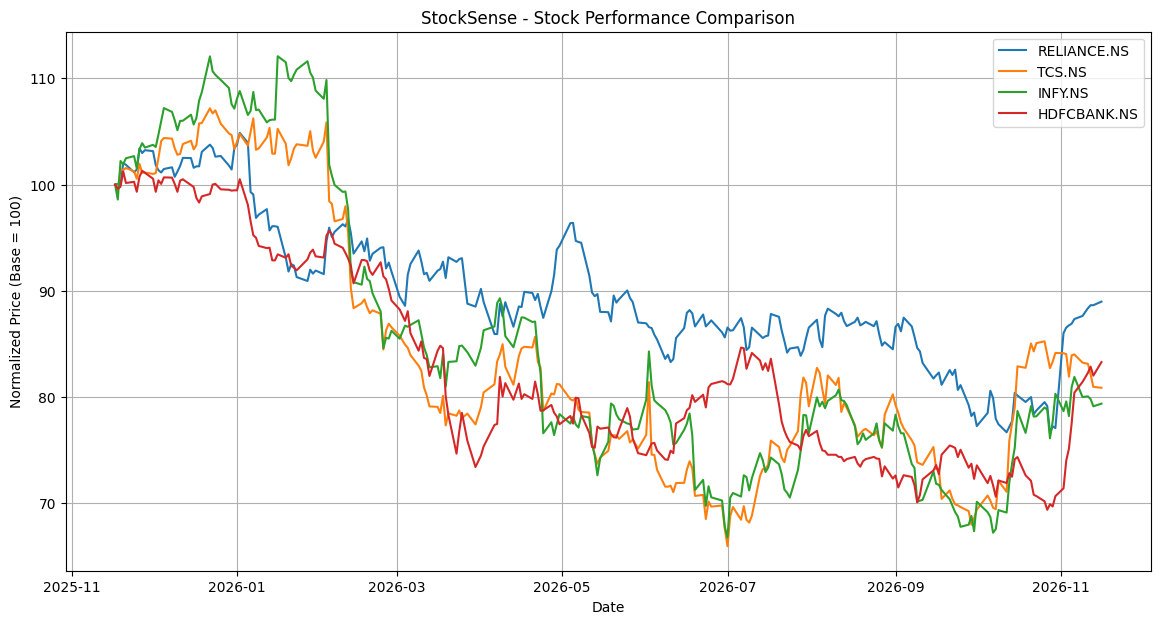

In [35]:

# STEP 34: MULTIPLE STOCK COMPARISON

symbols = [
    "RELIANCE.NS",
    "TCS.NS",
    "INFY.NS",
    "HDFCBANK.NS"
]

comparison_data = {}

for symbol in symbols:

    data = yf.download(
        symbol,
        period="1y",
        interval="1d",
        auto_adjust=True,
        progress=False
    )

    if data.empty:
        print("Data unavailable for:", symbol)
        continue

    if isinstance(data.columns, pd.MultiIndex):
        data.columns = data.columns.get_level_values(0)

    close = data["Close"]

    if isinstance(close, pd.DataFrame):
        close = close.iloc[:, 0]

    close = close.dropna()

    if len(close) > 0:
        normalized = (close / close.iloc[0]) * 100
        comparison_data[symbol] = normalized

comparison_df = pd.DataFrame(comparison_data)

print("Stock Comparison Data:")
print(comparison_df.tail())

# Plot comparison
plt.figure(figsize=(14, 7))

for symbol in comparison_df.columns:
    plt.plot(
        comparison_df.index,
        comparison_df[symbol],
        label=symbol
    )

plt.title("StockSense - Stock Performance Comparison")
plt.xlabel("Date")
plt.ylabel("Normalized Price (Base = 100)")
plt.legend()
plt.grid(True)
plt.show()


In [36]:

# STEP 35: EXPORT STOCK DATA

from google.colab import files

# Export analyzed Reliance data
stock_data.to_csv(
    "StockSense_Stock_Analysis.csv"
)

print("CSV file created successfully!")

files.download("StockSense_Stock_Analysis.csv")


CSV file created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:

# STEP 36: EXPORT STOCK COMPARISON

comparison_df.to_csv(
    "StockSense_Stock_Comparison.csv"
)

print("Stock comparison report created!")

files.download("StockSense_Stock_Comparison.csv")


Stock comparison report created!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:

# STEP 37: STOCKSENSE FINAL REPORT

report = f"""
========================================
       STOCKSENSE PROJECT REPORT
========================================

Project: AI-Powered Stock Market Trend Analysis

Stock Analyzed: RELIANCE.NS

Latest Closing Price: {latest_price:.2f}

Daily Price Change: {daily_change:.2f}%

RSI Value: {latest_rsi:.2f}

Market Trend: {latest_trend}

Machine Learning Model: Random Forest

Predicted Direction: {"UP" if prediction == 1 else "DOWN"}

Probability of UP: {probabilities[1]*100:.2f}%

Probability of DOWN: {probabilities[0]*100:.2f}%

========================================
Technology Used:
Python, Pandas, NumPy, Yahoo Finance,
Matplotlib, Plotly, Scikit-learn.

========================================
Disclaimer:
This project is developed for educational
and research purposes only.
========================================
"""

print(report)

with open("StockSense_Final_Report.txt", "w") as file:
    file.write(report)

files.download("StockSense_Final_Report.txt")



       STOCKSENSE PROJECT REPORT

Project: AI-Powered Stock Market Trend Analysis

Stock Analyzed: RELIANCE.NS

Latest Closing Price: 1344.80

Daily Price Change: 0.38%

RSI Value: 71.59

Market Trend: Bullish

Machine Learning Model: Random Forest

Predicted Direction: UP

Probability of UP: 57.21%

Probability of DOWN: 42.79%

Technology Used:
Python, Pandas, NumPy, Yahoo Finance,
Matplotlib, Plotly, Scikit-learn.

Disclaimer:
This project is developed for educational
and research purposes only.



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>